In [69]:
import pandas as pd
from matplotlib import pyplot as plt

In [70]:
data_df: pd.DataFrame = pd.read_csv("../data/insurance_us.csv")

In [71]:
display(data_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              5000 non-null   int64  
 1   Age                 5000 non-null   float64
 2   Salary              5000 non-null   float64
 3   Family members      5000 non-null   int64  
 4   Insurance benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


None

In [72]:
display(data_df.duplicated().sum())

153

In [73]:
display(data_df.describe())

,Gender,Age,Salary,Family members,Insurance benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


In [74]:
data_df.nunique().sort_values()

Gender                  2
Insurance benefits      6
Family members          7
Age                    46
Salary                524
dtype: int64

In [75]:
data_df.columns = (data_df.columns
                   .str.strip()
                   .str.lower()
                   .str.replace(" ","_")
)
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   float64
 2   salary              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


# Chapter 2 - Vectors and Vector Operations

## 2.2 (Chapter 2 Section 2)
2 - Creating Vectors

In [89]:
type(data_df["gender"])

pandas.core.series.Series

In [90]:
len(data_df["gender"])

5000

In [91]:
vector = data_df["gender"].to_numpy()
display(vector)

array([1, 0, 0, ..., 0, 1, 1])

In [92]:
type(vector)

numpy.ndarray

In [93]:
vector.dtype

dtype('int64')

In [94]:
len(vector)

5000

Quaisquer dados numéricos podem ser representados como um vetor.

Em Python, conjuntos de dados são frequentemente representados como listas. Em matemática, um conjunto ordenado de dados numéricos é um vetor, ou um vetor aritmético. As operações que podem ser executadas com números também podem ser feitas com vetores: adição, subtração e multiplicação. Em Python, operações com vetores são centenas de vezes mais rápidas comparadas a operações com listas.

Vamos passar para a biblioteca NumPy. Seu nome significa Numeric Python. A biblioteca fornece várias ferramentas para trabalhar com vetores. Nós já encontramos uma de suas funções - np.arange(). Neste curso, precisaremos da função np.array(). Não fique confuso com seu nome - um array é uma maneira útil de representar vetores em nosso código, e nós frequentemente usamos esses termos de maneira intercambiável.

Crie uma lista de dois números:

numbers1 = [2, 3]  # Lista de Python
print(numbers1)

[2, 3]

Converta a lista em um vetor.

import numpy as np

vector1 = np.array(numbers1)  # Vetor NumPy
print(vector1)

[2 3]

Crie mais um vetor sem uma variável temporária:

import numpy as np

vector2 = np.array([6, 2])
print(vector2)

[6 2]

Converta este vetor para uma lista:

numbers2 = list(vector2) # Lista a partir de um vetor
print(numbers2)

[6, 2]

A coluna da estrutura DataFrame de pandas é convertida para um vetor de NumPy usando o atributo values:

import pandas as pd

data = pd.DataFrame([1, 7, 3])
print(data[0].values)

[1 7 3]

Use a função len() para determinar o tamanho do vetor (o número de seus elementos):

print(len(vector2))

2

Vamos dar uma olhada em um exemplo concreto. Os visitantes da loja de roupas online LuxForVIP vêm de dois sites agregadores. O primeiro deles anuncia itens do mercado de baixo preço, enquanto o segundo agrega roupas de marcas de luxo. Os visitantes de LuxForVIP avaliam sua satisfação com os preços e a qualidade dos produtos em uma escala de 0 a 100. A tabela contém as avaliações de todos os visitantes. Uma pontuação alta dada ao preço indica que o cliente gostou do preço (ou seja, o item apresenta uma boa relação entre qualidade e preço). Da mesma forma, uma pontuação alta para a qualidade indica que o cliente considerou a qualidade como alta.

import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72], 
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62], 
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23], 
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])
print(ratings)

    Price    Quality
0       68        18
1       81        19
2       81        22
3       15        75
4       75        15
5       17        72
6       24        75
7       21        91
8       76        6
9       12        74
10     18        83
11     20        62
12     21        82
13     21        79
14     84        15
15     73        16
16     88        25
17     78        23
18     32        81
19     77        35

### 2.2.1

1.

Crie dois vetores. O primeiro contém todas as avaliações para o preço. O segundo tem avaliações para a qualidade. Imprima os resultados (em pré-código).

In [95]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

price = ratings["Price"].to_numpy()# < escreva o código aqui >
quality = ratings["Quality"].to_numpy()# < escreva o código aqui >

print('Preço: ', price)
print('Preço Type: ', type(price))
print('Qualidade: ', quality)
print('Qualidade Type: ', type(quality))

Preço:  [68 81 81 15 75 17 24 21 76 12 18 20 21 21 84 73 88 78 32 77]
Preço Type:  <class 'numpy.ndarray'>
Qualidade:  [18 19 22 75 15 72 75 91  6 74 83 62 82 79 15 16 25 23 81 35]
Qualidade Type:  <class 'numpy.ndarray'>


In [96]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

price = np.array([row[0] for row in ratings_values])# < escreva o código aqui >
quality = np.array([row[1] for row in ratings_values])# < escreva o código aqui >

print('Preço: ', price)
print('Preço Type: ', type(price))
print('Qualidade: ', quality)
print('Qualidade Type: ', type(quality))

Preço:  [68 81 81 15 75 17 24 21 76 12 18 20 21 21 84 73 88 78 32 77]
Preço Type:  <class 'numpy.ndarray'>
Qualidade:  [18 19 22 75 15 72 75 91  6 74 83 62 82 79 15 16 25 23 81 35]
Qualidade Type:  <class 'numpy.ndarray'>


In [97]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

price = np.asarray([row[0] for row in ratings_values])# < escreva o código aqui >
quality = np.asarray([row[1] for row in ratings_values])# < escreva o código aqui >

print('Preço: ', price)
print('Preço Type: ', type(price))
print('Qualidade: ', quality)
print('Qualidade Type: ', type(quality))

Preço:  [68 81 81 15 75 17 24 21 76 12 18 20 21 21 84 73 88 78 32 77]
Preço Type:  <class 'numpy.ndarray'>
Qualidade:  [18 19 22 75 15 72 75 91  6 74 83 62 82 79 15 16 25 23 81 35]
Qualidade Type:  <class 'numpy.ndarray'>


### 2.2.2

2.

Encontre o número total dos visitantes de LuxForVIP. Encontre o quinto vetor que contém avaliações de visitantes. Imprima os resultados (em pré-código).

In [98]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

visitors_count = len(ratings) # < escreva o código aqui >
visitor4 = ratings.iloc[4].to_numpy()# < escreva o código aqui >

print('Número de visitantes:', visitors_count)
print('Visitante 4:', visitor4)

Número de visitantes: 20
Visitante 4: [75 15]


In [99]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

print("ratings.shape", ratings.shape)
print("ratings.shape[0]",ratings.shape[0])
print("ratings.shape[1]",ratings.shape[1])
print("len(ratings)",len(ratings))
print("ratings.size",ratings.size)

ratings.shape (20, 2)
ratings.shape[0] 20
ratings.shape[1] 2
len(ratings) 20
ratings.size 40


### 2.2.3

3.

A tabela tem o atributo values.  values é um vetor bidimensional. Chame a função list() para converter esse vetor para uma lista de vetores com avaliações de todos os visitantes. Imprima os resultados (em pré-código).

In [100]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

vector_list = list(ratings.to_numpy())# < escreva o código aqui >
print(vector_list)

[array([68, 18]), array([81, 19]), array([81, 22]), array([15, 75]), array([75, 15]), array([17, 72]), array([24, 75]), array([21, 91]), array([76,  6]), array([12, 74]), array([18, 83]), array([20, 62]), array([21, 82]), array([21, 79]), array([84, 15]), array([73, 16]), array([88, 25]), array([78, 23]), array([32, 81]), array([77, 35])]


## 2.3 (Chapter 2 Section 3)

3. Vector Representation

Vamos visualizar vetores para analisar a lista de números no plano cartesiano.

Vamos construir um vetor bidimensional. Ele consiste de dois números: o primeiro é a coordenada ao longo do eixo horizontal x e o segundo é a coordenada para o eixo vertical y. O vetor pode ser representado por um ponto ou uma seta que conecta a origem ao ponto com as coordenadas (x, y).

O motivo para usar uma seta é que ela indica ambos os componentes de um vetor: magnitude e direção. Por exemplo, o vetor [2, 3] é um deslocamento de duas células à direita ao longo do eixo x e de três células para cima ao longo do eixo y. Se trabalharmos com vários vetores que se encontram ao longo da mesma linha, é melhor usar um ponto para representar cada vetor.

Por exemplo, vamos construir os vetores: vector1 — [2, 3] e vector2 — [6, 2] usando pontos. Nós usamos o método plt.plot() para desenhar pontos.

    import numpy as np
    import matplotlib.pyplot as plt

    vector1 = np.array([2, 3])
    vector2 = np.array([6, 2])

    plt.figure(figsize=(10, 10))
    plt.axis([0, 7, 0, 7])
    # o argumento 'ro' define o estilo do gráfico
    # 'r' - vermelho
    # 'o' - círculo
    plt.plot([vector1[0], vector2[0]], [vector1[1], vector2[1]], 'ro')
    plt.grid(True)
    plt.show()

image

 

Vamos usar setas para desenhar os mesmos vetores. Em vez de plt.plot(), chame plt.arrow().

    import numpy as np
    import matplotlib.pyplot as plt

    vector1 = np.array([2, 3])
    vector2 = np.array([6, 2])

    plt.figure(figsize=(10, 10))
    plt.axis([0, 7, 0, 7])
    plt.arrow(
        0,
        0,
        vector1[0],
        vector1[1],
        head_width=0.3,
        length_includes_head="True",
        color='b',
    )
    plt.arrow(
        0,
        0,
        vector2[0],
        vector2[1],
        head_width=0.3,
        length_includes_head="True",
        color='g',
    )
    plt.plot(0, 0, 'ro')
    plt.grid(True)
    plt.show()

image

O gráfico vetorial que acabamos de criar nos ajuda a visualizar tanto a direção quanto a magnitude de uma quantidade de vetores.

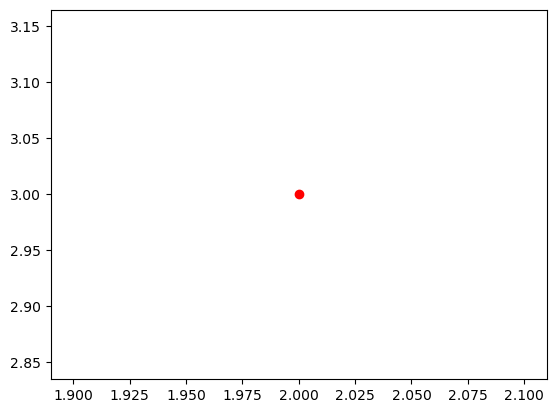

In [101]:
vector = np.array([2, 3])
x = vector[0]
y = vector[1]
plt.plot(x, y, 'ro')

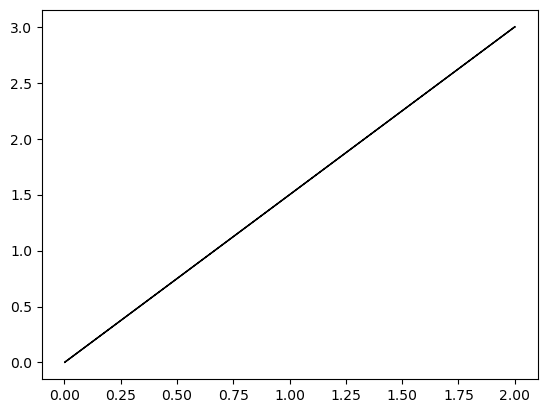

In [102]:
plt.arrow(
    0, 0,
    vector[0], vector[1]
)

### 2.3.1


1.

Construa o vetor [75, 15] do caso da LuxForVIP usando uma seta.


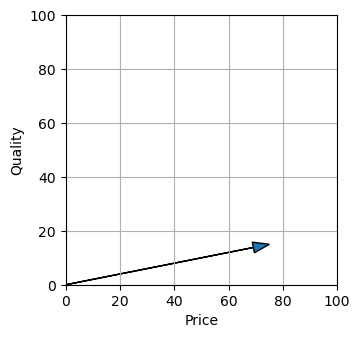

In [104]:
import numpy as np
import matplotlib.pyplot as plt

vector = np.array([75, 15])
plt.figure(figsize=(3.5,3.5))
plt.axis([0, 100, 0, 100])
plt.arrow(0,0,vector[0],vector[1], head_width=4,length_includes_head=True)# < escreva seu código aqui >, head_width=4, length_includes_head="True")
plt.xlabel('Price')
plt.ylabel('Quality')
plt.grid(True)
plt.show()

### 2.3.2


Construa todos os vetores bidimensionais com as avaliações dos visitantes da LuxForVIP usando pontos no plano.

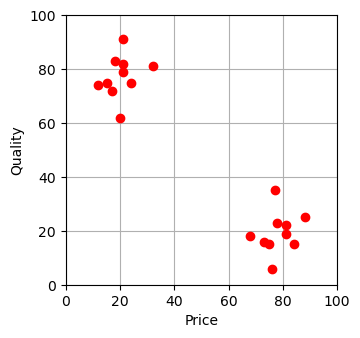

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

plt.figure(figsize=(3.5,3.5))
plt.axis([0, 100, 0, 100])
price = ratings['Price'].values
quality = ratings['Quality'].values
plt.plot(price,quality,'ro')# < escreva o código aqui >, 'ro')
plt.xlabel('Price')
plt.ylabel('Quality')
plt.grid(True)
plt.show()

### 2.3.3

3.

Baseado no gráfico da tarefa anterior, crie duas listas separadas de vetores bidimensionais contendo as avaliações dos visitantes: para aqueles que vieram do agregador do mercado atacadista e para aqueles que chegaram do agregador de luxo. Nomeie as variáveis visitors_1 e visitors_2. 

Para fazer isso, você vai precisar especificar os limiares de preço e qualidade que dividem os visitantes de ambos os agregadores. Depois, precisa aplicar esses limiares para separá-los nas variáveis mencionadas anteriormente.

Imprima seus valores na tela (em pré-código).

In [ ]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

visitors_1 = []
visitors_2 = []
for visitor in list(ratings.values):
    # < escreva o código aqui >
    if visitor[0] <= 40 and visitor[1] >= 60:
        visitors_1.append(visitor)
    else:
        visitors_2.append(visitor)

print('Avaliações dos visitantes do primeiro agregador:', visitors_1)
print('Avaliações dos visitantes do segundo agregador:', visitors_2)

Avaliações dos visitantes do primeiro agregador: [array([15, 75]), array([17, 72]), array([24, 75]), array([21, 91]), array([12, 74]), array([18, 83]), array([20, 62]), array([21, 82]), array([21, 79]), array([32, 81])]
Avaliações dos visitantes do segundo agregador: [array([68, 18]), array([81, 19]), array([81, 22]), array([75, 15]), array([76,  6]), array([84, 15]), array([73, 16]), array([88, 25]), array([78, 23]), array([77, 35])]


## 2.4 (Chapter 2 Section 4)

Vetores do mesmo tamanho podem ser somados e subtraídos um do outro

Quando você realiza operações de adição ou subtração com vetores, elas são executadas para cada elemento dos vetores. Para somar dois vetores, você precisa somar as coordenadas correspondentes dos vetores iniciais. Ao subtrair vetores, cada coordenada do vetor resultante é igual à diferença entre as coordenadas dos vetores iniciais.

VetorCoordenadasx⃗(x1,x2,…,xn)y⃗(y1,y2,…,yn)x⃗+y⃗(x1+y1,x2+y2,…,xn+yn)x⃗−y⃗(x1−y1,x2−y2,…,xn−yn)
Vetorx
y
​x
+y
​x
−y
​​Coordenadas(x1​,x2​,…,xn​)(y1​,y2​,…,yn​)(x1​+y1​,x2​+y2​,…,xn​+yn​)(x1​−y1​,x2​−y2​,…,xn​−yn​)​​

Some o vetor1 — [2, 3] e  o vetor2 — [6, 2]:

import numpy as np

vector1 = np.array([2, 3])
vector2 = np.array([6, 2])
sum_of_vectors = vector1 + vector2
print(sum_of_vectors)

[8 5]

Subtraia o vetor1 do vetor2:

subtraction = vector2 - vector1
print(subtraction)

[4 -1]

Construa os vetores recebidos no plano usando setas:

import numpy as np
import matplotlib.pyplot as plt

vector1 = np.array([2, 3])
vector2 = np.array([6, 2])
sum_of_vectors = vector1 + vector2
subtraction = vector2 - vector1

plt.figure(figsize=(10.2, 10))
plt.axis([0, 8.4, -2, 6])
arrow1 = plt.arrow(
    0,
    0,
    vector1[0],
    vector1[1],
    head_width=0.3,
    length_includes_head="True",
    color='b',
)
arrow2 = plt.arrow(
    0,
    0,
    vector2[0],
    vector2[1],
    head_width=0.3,
    length_includes_head="True",
    color='g',
)
arrow3 = plt.arrow(
    0,
    0,
    sum_of_vectors[0],
    sum_of_vectors[1],
    head_width=0.3,
    length_includes_head="True",
    color='r',
)
arrow4 = plt.arrow(
    0,
    0,
    subtraction[0],
    subtraction[1],
    head_width=0.3,
    length_includes_head="True",
    color='m',
)
plt.plot(0, 0, 'ro')
plt.legend(
    [arrow1, arrow2, arrow2, arrow3],
    ['vector1', 'vector2', 'sum_of_vectors', 'subtraction'],
    loc='upper left',
)
plt.grid(True)
plt.show()

image

Se construirmos um vetor igual ao vetor1 azul em termos de comprimento e direção igual ao fim do vetor2 verde, teremos o vetor vermelho (sum_of_vectors).

import numpy as np
import matplotlib.pyplot as plt

vector1 = np.array([2, 3])
vector2 = np.array([6, 2])
sum_of_vectors = vector1 + vector2

plt.figure(figsize=(10.2, 10))
plt.axis([0, 8.4, -2, 6])
arrow1 = plt.arrow(
    0,
    0,
    vector1[0],
    vector1[1],
    head_width=0.3,
    length_includes_head="True",
    color='b',
)
arrow2 = plt.arrow(
    0,
    0,
    vector2[0],
    vector2[1],
    head_width=0.3,
    length_includes_head="True",
    color='g',
)
arrow2new = plt.arrow(
    vector1[0],
    vector1[1],
    vector2[0],
    vector2[1],
    head_width=0.3,
    length_includes_head="True",
    color='g',
)
arrow3 = plt.arrow(
    0,
    0,
    sum_of_vectors[0],
    sum_of_vectors[1],
    head_width=0.3,
    length_includes_head="True",
    color='r',
)
plt.plot(0, 0, 'ro')
plt.legend(
    [arrow1, arrow2, arrow3],
    ['vector1', 'vector2', 'sum_of_vectors'],
    loc='upper left',
)
plt.grid(True)
plt.show()

image

O triângulo formado no gráfico acima dá um sentido geométrico à adição de vetores. Se cada vetor é um movimento em uma determinada direção, então a soma de dois vetores é o movimento ao longo do primeiro vetor seguido pelo movimento ao longo do segundo.

A diferença entre dois vetores é um passo - por exemplo, ao longo do vetor2 — seguido por um passo ao longo do vetor1 na direção oposta.

Construa o vetor subtração:

import numpy as np
import matplotlib.pyplot as plt

vector1 = np.array([2, 3])
vector2 = np.array([6, 2])
sum_of_vectors = vector1 + vector2
subtraction = vector2 - vector1

plt.figure(figsize=(10.2, 10))
plt.axis([0, 8.4, -2, 6])
arrow1 = plt.arrow(
    0,
    0,
    vector1[0],
    vector1[1],
    head_width=0.3,
    length_includes_head="True",
    color='b',
)
arrow2 = plt.arrow(
    0,
    0,
    vector2[0],
    vector2[1],
    head_width=0.3,
    length_includes_head="True",
    color='g',
)
arrow4 = plt.arrow(
    0,
    0,
    subtraction[0],
    subtraction[1],
    head_width=0.3,
    length_includes_head="True",
    color='m',
)
arrow1new = plt.arrow(
    vector2[0],
    vector2[1],
    -vector1[0],
    -vector1[1],
    head_width=0.3,
    length_includes_head="True",
    color='b',
)
plt.plot(0, 0, 'ro')
plt.legend(
    [arrow1, arrow2, arrow4],
    ['vector1', 'vector2', 'subtraction'],
    loc='upper left',
)
plt.grid(True)
plt.show()

image

Veja o exemplo: duas lojas online com uma variedade idêntica de mercadorias (capas e acessórios para celulares), 100Capas e Capas Para Você, planejam uma fusão. As tabelas contêm fragmentos de suas listas de estoque. As colunas representam nomes das mercadorias e suas quantidades.

image

Dê uma olhada no estoque da 100Capas:

import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity': quantity_1}, index=models)
print(stocks_1)

                                         Quantity
Silicone case for iPhone 8                  25
Leather case for iPhone 8                   63
Silicone case for iPhone XS                 80
Leather case for iPhone XS                  91
Silicone case for iPhone XS Max             81
Leather case for iPhone XS Max              55
Silicone case for iPhone 11                 14
Leather case for iPhone 11                  76
Silicone case for iPhone 11 Pro             33
Leather case for iPhone 11 Pro              71

Dê uma olhada no estoque da Capas Para Você:

quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity': quantity_2}, index=models)
print(stocks_2)

                                         Quantity
Silicone case for iPhone 8                  82
Leather case for iPhone 8                   24
Silicone case for iPhone XS                 92
Leather case for iPhone XS                  48
Silicone case for iPhone XS Max             32
Leather case for iPhone XS Max              45
Silicone case for iPhone 11                  4
Leather case for iPhone 11                  34
Silicone case for iPhone 11 Pro             12
Leather case for iPhone 11 Pro               1


### 2.4.1

1.

Pegue a coluna da quantidade de cada tabela e converta-as para um vetor. Imprima os resultados (em pré-código).

In [110]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity': quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity': quantity_2}, index=models)

vector_of_quantity_1 =  stocks_1["Quantity"].to_numpy()#< escreva o código aqui >
vector_of_quantity_2 =  stocks_2["Quantity"].to_numpy()#< escreva o código aqui >
print(
    'Estoque da primeira loja:',
    vector_of_quantity_1,
    '\nEstoque da segunda loja:',
    vector_of_quantity_2,
)

Estoque da primeira loja: [25 63 80 91 81 55 14 76 33 71] 
Estoque da segunda loja: [82 24 92 48 32 45  4 34 12  1]


### 2.4.2

2.

Encontre o vetor do estoque de 100Capas Para Você depois da junção.

Imprima os resultados (em pré-código).

In [116]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity' : quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity' : quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values

vector_of_quantity_united = vector_of_quantity_1+vector_of_quantity_2#(stocks_1+stocks_2).to_numpy()# < escreva o código aqui >
print(vector_of_quantity_united)

[107  87 172 139 113 100  18 110  45  72]


In [136]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity' : quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity' : quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values

united_df = stocks_1 + stocks_2

vector_of_quantity_united = (stocks_1+stocks_2)["Quantity"].to_numpy()# < escreva o código aqui >
print(vector_of_quantity_united)


[107  87 172 139 113 100  18 110  45  72]


### 2.4.3

3.

Crie um DataFrame para o estoque da loja depois da junção. Imprima os resultados (em pré-código).

In [137]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity' : quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity' : quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values
vector_of_quantity_united = vector_of_quantity_1 + vector_of_quantity_2

stocks_united = pd.DataFrame((stocks_1+stocks_2)# < escreva o código aqui >
                            )
print(stocks_united)

                                 Quantity
Silicone case for iPhone 8            107
Leather case for iPhone 8              87
Silicone case for iPhone XS           172
Leather case for iPhone XS            139
Silicone case for iPhone XS Max       113
Leather case for iPhone XS Max        100
Silicone case for iPhone 11            18
Leather case for iPhone 11            110
Silicone case for iPhone 11 Pro        45
Leather case for iPhone 11 Pro         72


## 2.5 (Chapter 2 Section 5)

Além de poderem ser somados e subtraídos, vetores também podem ser multiplicados por escalares.

Cada coordenada do vetor é multiplicada pelo mesmo número.

VetorCoordenadasx⃗(x1,x2,…,xn)kx⃗(kx1,kx2,…,kxn)
Vetorx
kx
​Coordenadas(x1​,x2​,…,xn​)(kx1​,kx2​,…,kxn​)​​

Se o número for negativo, todas as coordenadas também mudam seus sinais.

Primeiro, vamos multiplicar vetor1 — [2, 3] por um número positivo:

import numpy as np

vector1 = np.array([2, 3])
vector3 = 2 * vector1
print(vector3)

[4 6]

Agora vamos multiplicar por um número negativo:

vector4 = -1 * vector1
print(vector4)

[-2 -3]

Quando multiplicamos vetores por um número positivo, sua direção no plano permanece a mesma, mas o comprimento das setas muda. Quando multiplicamos por um número negativo, os vetores viram-se para a direção oposta, além de mudarem de tamanho.

import numpy as np
import matplotlib.pyplot as plt

vector1 = np.array([2, 3])
vector3 = 2 * vector1
vector4 = -1 * vector1

plt.figure(figsize=(10.2, 10))
plt.axis([-4, 6, -4, 6])
arrow1 = plt.arrow(
    0,
    0,
    vector1[0],
    vector1[1],
    head_width=0.3,
    length_includes_head="True",
    color='b',
)
arrow3 = plt.arrow(
    0,
    0,
    vector3[0],
    vector3[1],
    head_width=0.3,
    length_includes_head="True",
    color='g',
)
arrow4 = plt.arrow(
    0,
    0,
    vector4[0],
    vector4[1],
    head_width=0.3,
    length_includes_head="True",
    color='m',
)
plt.plot(0, 0, 'ro')
plt.legend(
    [arrow1, arrow3, arrow4],
    ['vector1', 'vector3', 'vector4'],
    loc='upper left',
)
plt.grid(True)
plt.show()

image

Aqui está um exemplo, adicionamos os preços aos dados da loja online depois da fusão.

import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity': quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity': quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values
vector_of_quantity_united = vector_of_quantity_1 + vector_of_quantity_2

stocks_united = pd.DataFrame(
    {'Quantity': vector_of_quantity_united}, index=models
)
stocks_united['Price'] = [30, 21, 32, 22, 18, 17, 38, 12, 23, 29]
print(stocks_united)

                                        Quantity  Price
Silicone case for iPhone 8               107       30
Leather case for iPhone 8                87        21
Silicone case for iPhone XS              172       32
Leather case for iPhone XS               139       22
Silicone case for iPhone XS Max          113       18
Leather case for iPhone XS Max           100       17
Silicone case for iPhone 11              18        38
Leather case for iPhone 11               110       12
Silicone case for iPhone 11 Pro          45        23
Leather case for iPhone 11 Pro           72        29

### 2.5.1

1.

Pegue a coluna de preços e converta-a para um vetor de números. Imprima os resultados (em pré-código).

In [138]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity' : quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity' : quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values
vector_of_quantity_united = vector_of_quantity_1 + vector_of_quantity_2

stocks_united = pd.DataFrame(
    {'Quantity': vector_of_quantity_united}, index=models
)
stocks_united['Price'] = [30, 21, 32, 22, 18, 17, 38, 12, 23, 29]

price_united = stocks_united['Price'].to_numpy()# < escreva o código aqui >
print(price_united)

[30 21 32 22 18 17 38 12 23 29]


### 2.5.2

2.

100Capas Para Você anunciou um desconto de 10% para todas as suas mercadorias. Encontre o novo vetor de preços levando o desconto em conta. Imprima os resultados (em pré-código).

In [139]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity': quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity': quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values
vector_of_quantity_united = vector_of_quantity_1 + vector_of_quantity_2

stocks_united = pd.DataFrame(
    {'Quantity': vector_of_quantity_united}, index=models
)
stocks_united['Price'] = [30, 21, 32, 22, 18, 17, 38, 12, 23, 29]

price_united = stocks_united['Price'].values

price_discount_10 =  0.90 * price_united# # < escreva o código aqui >
stocks_united['10% discount price'] = price_discount_10.astype(int)
print(stocks_united)

                                 Quantity  Price  10% discount price
Silicone case for iPhone 8            107     30                  27
Leather case for iPhone 8              87     21                  18
Silicone case for iPhone XS           172     32                  28
Leather case for iPhone XS            139     22                  19
Silicone case for iPhone XS Max       113     18                  16
Leather case for iPhone XS Max        100     17                  15
Silicone case for iPhone 11            18     38                  34
Leather case for iPhone 11            110     12                  10
Silicone case for iPhone 11 Pro        45     23                  20
Leather case for iPhone 11 Pro         72     29                  26


### 2.5.3

3.

Logo que a promoção acabou, 100Capas Para Você aumentou os preços em 10%. Cria uma lista de preços aumentados. Imprima os resultados (em pré-código).

In [142]:
import numpy as np
import pandas as pd

quantity_1 = [25, 63, 80, 91, 81, 55, 14, 76, 33, 71]
models = [
    'Silicone case for iPhone 8',
    'Leather case for iPhone 8',
    'Silicone case for iPhone XS',
    'Leather case for iPhone XS',
    'Silicone case for iPhone XS Max',
    'Leather case for iPhone XS Max',
    'Silicone case for iPhone 11',
    'Leather case for iPhone 11',
    'Silicone case for iPhone 11 Pro',
    'Leather case for iPhone 11 Pro',
]
stocks_1 = pd.DataFrame({'Quantity': quantity_1}, index=models)
quantity_2 = [82, 24, 92, 48, 32, 45, 4, 34, 12, 1]
stocks_2 = pd.DataFrame({'Quantity': quantity_2}, index=models)

vector_of_quantity_1 = stocks_1['Quantity'].values
vector_of_quantity_2 = stocks_2['Quantity'].values
vector_of_quantity_united = vector_of_quantity_1 + vector_of_quantity_2

stocks_united = pd.DataFrame(
    {'Quantity': vector_of_quantity_united}, index=models
)
stocks_united['Price'] = [30, 21, 32, 22, 18, 17, 38, 12, 23, 29]

price_united = stocks_united['Price'].values
price_discount_10 = price_united * 0.9
stocks_united['10% discount prise'] = price_discount_10.astype(int)

price_no_discount = price_discount_10 *1.1# < escreva o código aqui >
stocks_united['10% raise price'] = price_no_discount.astype(int)
print(stocks_united)

                                 Quantity  Price  10% discount prise  \
Silicone case for iPhone 8            107     30                  27   
Leather case for iPhone 8              87     21                  18   
Silicone case for iPhone XS           172     32                  28   
Leather case for iPhone XS            139     22                  19   
Silicone case for iPhone XS Max       113     18                  16   
Leather case for iPhone XS Max        100     17                  15   
Silicone case for iPhone 11            18     38                  34   
Leather case for iPhone 11            110     12                  10   
Silicone case for iPhone 11 Pro        45     23                  20   
Leather case for iPhone 11 Pro         72     29                  26   

                                 10% raise price  
Silicone case for iPhone 8                    29  
Leather case for iPhone 8                     20  
Silicone case for iPhone XS                   31  
Lea

## 2.6 (Chapter 2 Section 6)

Vamos descobrir como calcular o valor médio de um conjunto de vetores. Este valor vai representar a média para um conjunto de pontos de dados armazenados em um vetor.

Se vetores individuais de um conjunto, por exemplo, descrevem clientes por características, então o valor médio de vetores frequentemente descreve um cliente típico ou estatisticamente médio.

Para o conjunto de vetores 𝑎1,𝑎2…𝑎𝑛
a1​,a2​…an​ (onde n
n é o número total de vetores), o valor médio de vetores é a soma de todos os vetores multiplicada por 1𝑛
n1​. Isso resulta em um novo vetor aˉ
aˉ:

aˉ=1n(a1+a2+⋯+an)
aˉ=n1​(a1​+a2​+⋯+an​)

Se o conjunto consistir de apenas um vetor (𝑛=1
n=1), ele será igual à média: 𝑎=𝑎1
a=a1​. O valor médio de dois vetores é 𝑎=𝑎1+𝑎22
a=2a1​+a2​​. O valor médio para um par de vetores bidimensionais é o meio do segmento que conecta 𝑎1
a1​ e 𝑎2
a2​.

Encontre a média para vector1 — [2, 3] e vector2 — [6, 2]:

import numpy as np

vector1 = np.array([2, 3])
vector2 = np.array([6, 2])
vector_mean = 0.5 * (vector1 + vector2)
print(vector_mean)

[4.  2.5]

Chamamos o valor médio de vector_mean. A primeira coordenada do novo vetor é o valor médio das primeiras coordenadas de vector1 e vector2, e a segunda coordenada é o valor médio das segundas coordenadas de vector1 e vector2.

Vamos desenhar esses vetores no plano. Construa o vetor vector1 + vector2 e depois o multiplique por 0.5.

import numpy as np
import matplotlib.pyplot as plt

vector1 = np.array([2, 3])
vector2 = np.array([6, 2])
vector_mean = 0.5 * (vector1 + vector2)

plt.figure(figsize=(10, 10))
plt.axis([0, 8.4, -1, 6])
arrow1 = plt.arrow(
    0,
    0,
    vector1[0],
    vector1[1],
    head_width=0.3,
    length_includes_head="True",
    color='b',
)
arrow2 = plt.arrow(
    0,
    0,
    vector2[0],
    vector2[1],
    head_width=0.3,
    length_includes_head="True",
    color='g',
)
arrow_sum = plt.arrow(
    0,
    0,
    vector1[0] + vector2[0],
    vector1[1] + vector2[1],
    head_width=0.3,
    length_includes_head="True",
    color='r',
)
arrow_mean = plt.arrow(
    0,
    0,
    vector_mean[0],
    vector_mean[1],
    head_width=0.3,
    length_includes_head="True",
    color='m',
)
plt.plot(vector1[0], vector1[1], 'ro')
plt.plot(vector2[0], vector2[1], 'ro')
plt.plot(vector_mean[0], vector_mean[1], 'ro')
plt.legend(
    [arrow1, arrow2, arrow_sum, arrow_mean],
    ['vector1', 'vector2', 'vector1+vector2', 'vector_mean'],
    loc='upper left',
)
plt.grid(True)
plt.show()

image

Vamos tentar calcular a avaliação média dos visitantes da famosa loja LuxForVIP.

Para calcular a avaliação média de preços, use a função sum(). Ela encontrará a soma de todos os elementos do vetor.

import numpy as np
import pandas as pd

ratings_values = [
    [68, 18],
    [81, 19],
    [81, 22],
    [15, 75],
    [75, 15],
    [17, 72],
    [24, 75],
    [21, 91],
    [76, 6],
    [12, 74],
    [18, 83],
    [20, 62],
    [21, 82],
    [21, 79],
    [84, 15],
    [73, 16],
    [88, 25],
    [78, 23],
    [32, 81],
    [77, 35],
]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

price = ratings['Price'].values  # vetor NumPy com todas as avaliações de preços
sum_prices = sum(price)  # soma de todas as avaliações de preços
average_price_rat = sum(price) / len(price)  # valor médio das avaliações de preços
print(average_price_rat)

49.1

### 2.6.1

1.

Encontre a avaliação média da qualidade. Imprima os resultados (em pré-código).

Use np.ndarray

In [144]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

# < escreva o código aqui >

average_quality_rat =  sum(ratings["Quality"].to_numpy())/len(ratings["Quality"].to_numpy())# < escreva o código aqui >
print(average_quality_rat)

48.4


### 2.6.2

2.

Combine as avaliações médias de qualidade e preço para todos os visitantes em um vetor. Imprima os resultados (em pré-código).



In [146]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

price = ratings['Price'].values
sum_prices = sum(price)
average_price_rat = sum(price) / len(price)

quality = ratings['Quality'].values
average_quality_rat = sum(quality) / len(quality)

average_rat = np.array([average_price_rat,average_quality_rat]) # < escreva o código aqui >
print(average_rat)

[49.1 48.4]


### 2.6.3
3.

No plano cartesiano, indique o valor obtido. O vetor resultante pode ser considerado a avaliação do visitante médio? Imprima os resultados (em pré-código).

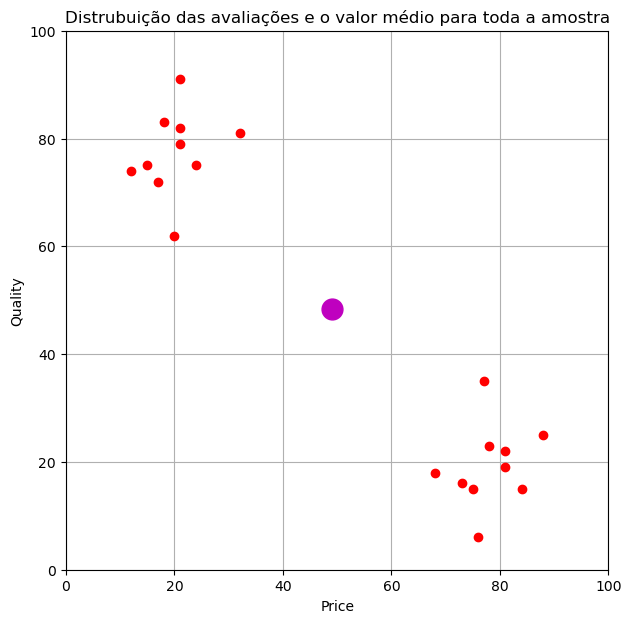

In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

price = ratings['Price'].values
sum_prices = sum(price)
average_price_rat = sum(price) / len(price)

quality = ratings['Quality'].values
average_quality_rat = sum(quality) / len(quality)
average_rat = np.array([average_price_rat, average_quality_rat])

plt.figure(figsize=(7, 7))
plt.axis([0, 100, 0, 100])
plt.plot(average_rat[0],average_rat[1],'mo', markersize=15)# < escreva o código aqui >, 'mo', markersize=15)
plt.plot(price, quality, 'ro')
plt.xlabel('Price')
plt.ylabel('Quality')
plt.grid(True)
plt.title('Distrubuição das avaliações e o valor médio para toda a amostra')
plt.show()

### 2.6.4
4.

Calcule separadamente avaliações médias para os visitantes que chegaram do agregador do mercado atacadista e para aqueles que vieram do agregador de marcas de luxo. Imprima os resultados (em pré-código).



In [151]:
import numpy as np
import pandas as pd

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])

clients_1 = []
clients_2 = []
for client in list(ratings.values):
    if client[0] < 40 and client[1] > 60:
        clients_1.append(client)
    else:
        clients_2.append(client)

average_client_1 = sum(clients_1) / len(clients_1)
print('Avaliação média do primeiro agregador: ', average_client_1)

average_client_2 = sum(clients_2) / len(clients_2)# < escreva o código aqui >
print('Avaliação média do segundo agregador: ', average_client_2)

Avaliação média do primeiro agregador:  [20.1 77.4]
Avaliação média do segundo agregador:  [78.1 19.4]


### 2.6.5

5.

No diagrama com avaliações de visitantes individuais, indique os valores obtidos. Cada uma das médias obtidas pode ser considerada a avaliação do visitante médio para o respectivo grupo? Imprima os resultados (em pré-código).

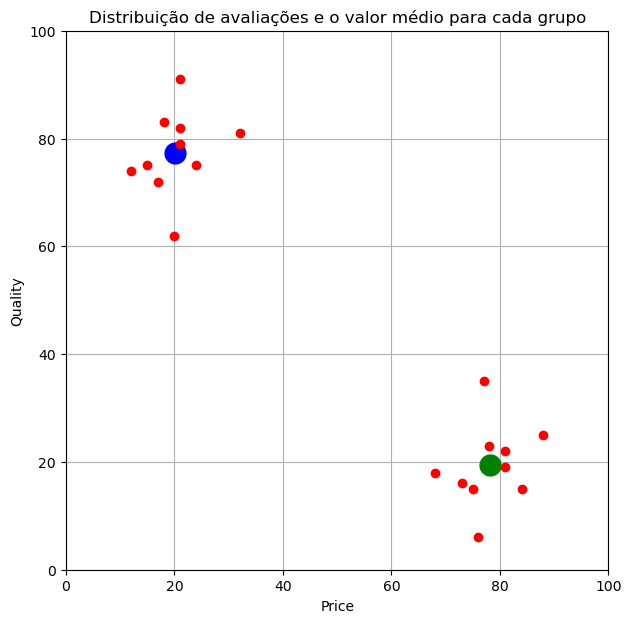

In [155]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ratings_values = [
    [68,18], [81,19], [81,22], [15,75], [75,15], [17,72],
    [24,75], [21,91], [76, 6], [12,74], [18,83], [20,62],
    [21,82], [21,79], [84,15], [73,16], [88,25], [78,23],
    [32, 81], [77, 35]]
ratings = pd.DataFrame(ratings_values, columns=['Price', 'Quality'])
price = ratings['Price'].values
quality = ratings['Quality'].values

clients_1 = []
clients_2 = []
for client in list(ratings.values):
    if client[0] < 40 and client[1] > 60:
        clients_1.append(client)
    else:
        clients_2.append(client)

average_client_1 = sum(clients_1)/len(clients_1)

average_client_2 = sum(clients_2)/len(clients_2)

plt.figure(figsize=(7, 7))
plt.axis([0, 100, 0, 100])

# desenhe a média para o grupo 1
# 'b' - blue (azul)
plt.plot(average_client_1[0],average_client_1[1],'bo', markersize=15)# < escreva o código aqui >,

# desenhe a média para o grupo 2
# 'g' - green (verde)
plt.plot(average_client_2[0],average_client_2[1],'go', markersize=15) # < escreva o código aqui >,

plt.plot(price, quality, 'ro')
plt.xlabel('Price')
plt.ylabel('Quality')
plt.grid(True)
plt.title('Distribuição de avaliações e o valor médio para cada grupo')
plt.show()

## 2.7 (Chapter 2 Section 7)

Vetores podem ser usados para escrever funções. Tais funções são chamadas de funções vetorizadas. Elas nos ajudam a fazer operações em um vetor inteiro de uma maneira eficiente.

As ferramentas do NumPy permitem-nos a realizar várias operações com vetores. Se usarmos o método np.array() para criar um vetor, depois vamos poder multiplicar e dividir dois vetores do mesmo tamanho. Como resultado, obteremos um novo vetor do mesmo tamanho:

import numpy as np

array1 = np.array([2, -4, 6, -8])
array2 = np.array([1, 2, 3, 4])
array_mult = array1 * array2
array_div = array1 / array2
print('Produto de dois vetores: ', array_mult)
print('Divisão de dois vetores: ', array_div)

Produto de dois vetores:  [  2  -8  18 -32]
Divisão de dois vetores:  [ 2. -2.  2. -2.]

Se operações aritméticas forem realizadas entre um vetor e um número único, então a ação é aplicada a cada elemento do vetor. E novamente, um vetor do mesmo tamanho é criado.

Vamos ver como vai ficar quando realizarmos adição, subtração e divisão em um vetor com um escalar:

import numpy as np

array2 = np.array([1, 2, 3, 4])
array2_plus_10 = array2 + 10
array2_minus_10 = array2 - 10
array2_div_10 = array2 / 10
print('Soma: ', array2_plus_10)
print('Diferença: ', array2_minus_10)
print('Divisão: ', array2_div_10)

Soma:  [11 12 13 14]
Diferença:  [-9 -8 -7 -6]
Divisão:  [0.1 0.2 0.3 0.4]

O mesmo princípio - elemento por elemento - funciona para vetores quando nós lidamos com operações matemáticas padrão, como operações com expoentes ou logaritmos.

Vamos elevar o vetor à segunda potência:

import numpy as np

numbers_from_0 = np.array([0, 1, 2, 3, 4])
squares = numbers_from_0 ** 2
print(squares)

[ 0  1  4  9 16]

Você também pode usar listas e ciclos para fazer tudo isso, mas as operações com vetores em NumPy são muito mais rápidas. Uma maneira muito útil de aproveitar esse poder dos vetores NumPy é escrever funções. Podemos passar vetores como entradas para funções exatamente da mesma maneira como passamos dados de outros tipos.

Veja o exemplo: temos um vetor de valores e, para os propósitos de nossa análise, precisamos escalar os dados. Cada elemento do vetor deve ser dimensionado para um número entre 0 e 1, onde o valor mínimo no vetor é 0 e o máximo é 1. Aqui está a fórmula que podemos usar para tal função:

f(x)=x−MINMAX−MIN
f(x)=MAX−MINx−MIN​

Para aplicar essa função a todos os elementos de um vetor, chamamos os métodos max() e min() para encontrar seus valores mínimo e máximo. Uma vez que a função é definida, podemos passar-lhe um vetor de números. Como resultado, teremos um vetor do mesmo comprimento, mas com elementos convertidos:

import numpy as np


def min_max_scale(values):
    return (values - min(values)) / (max(values) - min(values))


our_values = np.array([-20, 0, 0.5, 80, -1])
print(min_max_scale(our_values))

[0.    0.2   0.205 1.    0.19 ]

Às vezes, os valores podem ser arbitrariamente grandes. Nesses casos, uma função de dimensionamento baseada nos valores mínimo e máximo não será eficaz. Podemos resolver este problema usando a função logística ou transformação logística:

f(x)=11+exp(−x)
f(x)=1+exp(−x)1​

onde exp⁡()
exp() é a função exponencial (de lat. exponere, "expor"). Ela eleva e
e, o número de Euler, à potência do argumento. O número chama-se assim em homenagem ao grande matemático suiço Leonhard Euler e é aproximadamente igual a 2.718281828.

image

### 2.7.1

Escreva a função logistic_transform() para fazer a transformação logística. Aplique-a a todos os elementos do vetor. Imprima os resultados (em pré-código).

In [ ]:
import numpy as np


def logistic_transform(values):
    return 1/(1+np.exp(-values))# < escreva o código aqui >


our_values = np.array([-20, 0, 0.5, 80, -1])
print(logistic_transform(our_values))

## 2.8 (Chapter 2 Section 8)

Vamos escrever funções que permitem avaliar métricas usando vetores.

Como podemos aplicar vetorização em métricas de avaliação? Vejamos um exemplo. Armazene um conjunto de valores reais na variável target e valores preditos na variável predictions. Ambos os conjuntos são do tipo np.array.

import numpy as np

target = np.array([0.9, 1.2, 1.4, 1.5, 1.9, 2.0])
predictions = np.array([1.0, 1.2, 1.4, 1.6, 1.8, 2.0])

Use os métodos NumPy padrão para calcular as métricas de avaliação:

    sum() — (para encontrar a soma dos elementos de um vetor)
    mean() — (para calcular o valor médio)

Chame-as da seguinte forma: <array name>.sum() e <array name>.mean().

Por exemplo, aqui está a fórmula para calcular o erro quadrático médio (EQM):

MSE=1n∑i=1n(targeti−predictionsi)2
MSE=n1​∑i=1n​(targeti​−predictionsi​)2

onde 𝑛
n é o comprimento de cada array e Σ
Σ é o somatório de todas as observações da amostra (𝑖
i varia de 1 a 𝑛
n). Os elementos ordinais dos vetores target e predictions são denotados por targeti
targeti​ e predictionsi
predictionsi​.

Escreva a fórmula usando sum():

def mse1(target, predictions):
    n = target.size
    return ((target - predictions) ** 2).sum() / n

Vamos escrever a fórmula do EQM usando mean():

def mse2(target, predictions):
    return ((target - predictions) ** 2).mean()

Para nos certificarmos de que os resultados batem certo, aplique ambas as funções do EQM aos vetores target e predictions.

print(mse1(target, predictions), mse2(target, predictions))

0.0049999999999999975 0.0049999999999999975

Os resultados batem certo!

1.

Escreva a função para calcular EAM usando mean(). Encontre o EAM e imprima os resultados (em pré-código).

MAE=1n∑i=1n∣targeti−predictionsi∣
MAE=n1​∑i=1n​∣targeti​−predictionsi​∣

In [156]:
import numpy as np


def mae(target, predictions):
    return np.sum(np.abs(target - predictions))/len(target)# < escreva o código aqui >


target = np.array([0.9, 1.2, 1.4, 1.5, 1.9, 2.0])
predictions = np.array([1.0, 1.2, 1.4, 1.6, 1.8, 2.0])
print(mae(target, predictions))

0.04999999999999999


In [159]:
import numpy as np


def mae(target, predictions):
    return np.abs(target - predictions).mean()# < escreva o código aqui >


target = np.array([0.9, 1.2, 1.4, 1.5, 1.9, 2.0])
predictions = np.array([1.0, 1.2, 1.4, 1.6, 1.8, 2.0])
print(mae(target, predictions))

0.04999999999999999


### 2.8.2

2.

Calcule o REQM usando a fórmula:

RMSE=MSE=1n∑i=1n(targeti−predictionsi)2
RMSE=MSE
​
=n1​∑i=1n​(targeti​−predictionsi​)2
​

Imprima os resultados (em pré-código).

In [164]:
import numpy as np


def rmse(target, predictions):
    return np.sqrt(((target-predictions) ** 2).mean()) # < escreva o código aqui >


target = np.array([0.9, 1.2, 1.4, 1.5, 1.9, 2.0])
predictions = np.array([1.0, 1.2, 1.4, 1.6, 1.8, 2.0])
print(rmse(target, predictions))

0.07071067811865474


# Chapter 3 - Distância entre Vetores

## 3.1 (Chapter 3 Section 1)

Introdução
Vamos aprender como calcular a distância entre vetores. Isso nos ajudará a criar um modelo completo de aprendizado de máquina.

Entender distâncias entre vetores nos ajuda a aprender como funcionam algoritmos de aprendizado de máquina baseados em distâncias. Alguns desses algoritmos de aprendizado de máquina usados para modelagem são o algoritmo de K-vizinhos mais próximos (KNN), o algoritmo de agrupamento K-Means e a Máquina de Vetores de Suporte (MVS). Esses três algoritmos fazem uso da distância euclidiana, um método importante para medir distâncias entre vetores que iremos observar neste capítulo.

O conhecimento de como estes algoritmos funcionam nos ajudará a saber como aprimorar os parâmetros de nosso modelo para alcançar, por exemplo, um melhor resultado de acurácia.
Resumo do Capítulo

Agora vamos começar nossa jornada de aprendizagem e conhecer como calcular várias distâncias entre vetores, aprender sobre o produto escalar e descobrir como funciona um dos algoritmos baseados em distâncias - o Algoritmo KNN. Depois, antes de encerrarmos o capítulo, vamos ver como podemos criar um modelo personalizado usando classes de Python e as distâncias que teremos aprendido.
Você irá:

    Calcular um produto escalar usando numpy.dot() e o operador de multiplicação de matrizes.
    Calcular a distância Euclidiana usando numpy.dot() e euclidean().
    Calcular a distância Manhattan usando a função cityblock().
    Diferenciar as distâncias Euclidiana e de Manhattan.
    Determinar a distância entre vetores multidimensionais usando as distâncias Euclidiana e de Manhattan.
    Usar a distância Euclidiana para implementar o algoritmo dos vizinhos mais próximos.
    Desenvolver uma classe de Python para criar um modelo de aprendizado de máquina.

Quanto tempo irá demorar:

Oito lições, 10-15 minutos cada.

## 3.2 (Chapter 3 Section 2)

Produto Escalar

Vamos descobrir o que é um produto escalar e como calculá-lo.

Imagine que você é um contador que trabalha para uma startup e queria determinar o valor total que deve ser pago a todos os consultores que trabalharam para a empresa durante o mês anterior.

Os dados que você precisa estão contidos em dois vetores: no_of_hours e hourly_rate. O vetor no_of_hours contém o número de horas de trabalho de todos os consultores, enquanto o vetor hourly_rate contém o preço por hora para cada consultor respectivamente.

import numpy as np

no_of_hours = np.array([160, 150, 80, 95, 60, 40])
hourly_rate = np.array([30, 35, 40, 40, 45, 50])

Para determinar o valor total, você precisará fazer o seguinte cálculo:

print(sum(no_of_hours * hourly_rate))

21750

O valor total que a startup precisa pagar aos consultores é $21.750.

Nós multiplicamos todos os componentes e depois somamos os valores obtidos. Também podemos descrever isso de outra forma dizendo que nós calculamos o produto escalar. Como resultado desta operação, obtivemos um novo número. Este número é um escalar. Ao contrário de vetores, que contêm mais de um tipo de informação (por exemplo, magnitude e direção), escalares são unidimensionais.

Aqui está a fórmula para o produto escalar de dois vetores 𝑎=[𝑥1,𝑥2…𝑥𝑛]
a=[x1​,x2​…xn​] e 𝑏=[𝑦1,𝑦2…𝑦𝑛]
b=[y1​,y2​…yn​]:

Observe que os vetores devem ser do mesmo tamanho.

a⋅b=x1∗y1+x2∗y2+⋯+xn∗yn
a⋅b=x1​∗y1​+x2​∗y2​+⋯+xn​∗yn​

O produto escalar dos vetores a
a e b
b geralmente é indicado por parênteses  ⟨𝑎,𝑏⟩
⟨a,b⟩ ou por um ponto 𝑎⋅𝑏
a⋅b.

Encontre o mesmo produto escalar usando a função numpy.dot() e certifique-se de que os resultados correspondem.

import numpy as np

no_of_hours = np.array([160, 150, 80, 95, 60, 40])
hourly_rate = np.array([30, 35, 40, 40, 45, 50])

print(np.dot(no_of_hours , hourly_rate ))

21750

O operador de multiplicação de matrizes nos permite calcular o produto ainda mais facilmente. O operador é denotado por @.

import numpy as np

no_of_hours = np.array([160, 150, 80, 95, 60, 40])
hourly_rate = np.array([30, 35, 40, 40, 45, 50])

print(no_of_hours @ hourly_rate )

21750

Os resultados do cálculo são iguais para todos os métodos.

O produto escalar, uma operação matemática aplicada em vetores, é uma das várias metodologias para a combinação de vetores e desempenha um papel fundamental em diversas aplicações práticas. Para os nossos propósitos, a maneira mais importante de usar o produto escalar é para calcular distâncias entre vetores. Essa aplicação do produto é essencial para algoritmos de aprendizado de máquina baseados em distâncias.

Vamos ver outro exemplo. O vetor 𝑞
q contém a quantidade de unidades de cada modelo de fones de ouvido no armazém. O vetor 𝑐
c contém os preços dessas mercadorias. O valor total de todos os itens é a soma dos resultados de multiplicação da quantidade de cada produto e de seu preço, ou em termos mais simples, o produto escalar (𝑞,𝑐)
(q,c). 

A tabela abaixo contém quantidades e preços de modelos de fones de ouvido para duas lojas da cadeia de varejo Fonetismo.

import numpy as np
import pandas as pd

store1_price = [
    209.9,
    119.9,
    53.9,
    31.9,
    19.9,
    109.9,
    59.99,
    22.9,
    81.11,
    32.9,
]
store1_quantity = [19, 11, 8, 15, 23, 7, 14, 9, 10, 4]

store2_price = [209.9, 124.9, 42.9, 27.9, 23.9, 109.9, 49.9, 24.9, 89.9, 32.9]
store2_quantity = [10, 16, 20, 9, 18, 12, 10, 11, 18, 22]

models = [
    'Apple AirPods Pro',
    'Apple AirPods MV7N2RU/A',
    'JBL Tune 120TWS',
    'JBL TUNE 500BT',
    'JBL JR300BT',
    'Huawei Freebuds 3',
    'Philips TWS SHB2505',
    'Sony WH-CH500',
    'Sony WF-SP700N',
    'Sony WI-XB400',
]
items1 = pd.DataFrame(
    {'Price': store1_price, 'Quantity': store1_quantity}, index=models
)
items2 = pd.DataFrame(
    {'Price': store2_price, 'Quantity': store2_quantity}, index=models
)

print('Store 1\n', items1, '\n')
print('Store 2\n', items2)

Store 1
                           Price  Quantity
Apple AirPods Pro        209.9          19
Apple AirPods MV7N2RU/A  119.9          11
JBL Tune 120TWS           53.9           8
JBL TUNE 500BT            31.9          15
JBL JR300BT               19.9          23
Huawei Freebuds 3        109.9           7
Philips TWS SHB2505       59.99         14
Sony WH-CH500             22.9           9
Sony WF-SP700N            81.11         10
Sony WI-XB400             3290           4 

Store 2
                           Price  Quantity
Apple AirPods Pro        209.9          10
Apple AirPods MV7N2RU/A  124.9          16
JBL Tune 120TWS           42.9          20
JBL TUNE 500BT            27.9           9
JBL JR300BT               23.9          18
Huawei Freebuds 3        109.9          12
Philips TWS SHB2505       49.9          10
Sony WH-CH500             24.9          11
Sony WF-SP700N            89.9          18
Sony WI-XB400             32.9          22

### 3.2.1

Encontre o valor total dos itens para cada loja da Fonetismo. Salve os valores nas variáveis items1_value e items2_value.

Encontre o valor total dos itens em ambas as lojas e salve-o na variável total_value. Imprima os resultados (em pré-código).

In [165]:
import numpy as np
import pandas as pd

store1_price = [209.9, 119.9, 53.9, 31.9, 19.9, 109.9, 59.99, 22.9, 81.11, 32.9]
store1_quantity = [19, 11, 8, 15, 23, 7, 14, 9, 10, 4]

store2_price = [209.9, 124.9, 42.9, 27.9, 23.9, 109.9, 49.9, 24.9, 89.9, 32.9]
store2_quantity = [10, 16, 20, 9, 18, 12, 10, 11, 18, 22]

models = ['Apple AirPods Pro',
          'Apple AirPods MV7N2RU/A',
          'JBL Tune 120TWS',
          'JBL TUNE 500BT',
          'JBL JR300BT',
          'Huawei Freebuds 3',
          'Philips TWS SHB2505',
          'Sony WH-CH500',
          'Sony WF-SP700N',
          'Sony WI-XB400',
         ]
items1 = pd.DataFrame({'Price':store1_price,
                        'Quantity':store1_quantity}, index=models)
items2 = pd.DataFrame({'Price':store2_price,
                        'Quantity':store2_quantity}, index=models)

items1_price = items1['Price'].values
items1_quantity = items1['Quantity'].values

items2_price = items2['Price'].to_numpy()# < escreva o código aqui >
items2_quantity = items2['Quantity'].to_numpy()# < escreva o código aqui >

# valor dos itens para a loja 1
items1_value = items1_price @ items1_quantity# < escreva o código aqui >

# valor dos itens para a loja 2
items2_value = items2_price @ items2_quantity# < escreva o código aqui >

total_value = items1_value + items2_value# < escreva o código aqui >

print('Valor total dos itens das duas lojas:', total_value, 'USD')

Valor total dos itens das duas lojas: 19502.760000000002 USD


## 3.3 (Chapter 3 Section 3)

Distância Euclidiana

Nesta lição, aprenderemos como usar o produto escalar para encontrar a distância entre pontos no plano.

Primeiro, vamos dar uma olhada no vetor a=(x,y)
a=(x,y). Como podemos descobrir seu comprimento? A primeira coisa que podemos fazer é imaginar que nosso vetor é a hipotenusa de um triângulo retângulo. Isso é útil porque, se nos lembrarmos um pouco das propriedades de triângulos retângulos, poderemos usar o teorema de Pitágoras para encontrar o comprimento do nosso vetor.

Ok, fantástico, mas você deve estar se perguntando o que isso tem a ver com o produto escalar. Bem, veja o que acontece quando você calcular o produto escalar de um vetor e ele mesmo:

a⋅a=(x∗x)+(y∗y)=x2+y2
a⋅a​=(x∗x)+(y∗y)=x2+y2​

Se tirarmos a raiz quadrada disso, teremos o mesmo resultado que recebemos usando o teorema de Pitágoras.

=x2+y2
=x2+y2
​

Muito legal, não é mesmo? A melhor parte deste fato é que isso nos dá uma maneira prática de calcular comprimentos de vetores usando np.dot():

import numpy as np

a = np.array([5, 6])

# usando o teorema de Pitágoras
print(((a[0] ** 2) + (a[1] ** 2)) ** 0.5)

print()
# usando o produto escalar -- fica mais bonito, não é?
print(np.dot(a, a) ** 0.5)

7.810249675906654

7.810249675906654

Agora, podemos usar esta informação para encontrar a diferença entre dois vetores - o vetor a
a e o vetor b
b.

Como você pode ver, podemos pensar na diferença entre os dois vetores como um novo vetor (b−a)
(b−a). Depois, usando o nosso truque de antes, podemos calcular o comprimento deste vetor:

d2(a,b)=(b−a)⋅(b−a)=(x2−x1)2+(y2−y1)2
d2​(a,b)​=(b−a)⋅(b−a)
​=(x2​−x1​)2+(y2​−y1​)2
​​

Esta medida de distância é chamada de distância Euclidiana, usada em muitos algoritmos de aprendizado de máquina como a métrica padrão de distância. A distância Euclidiana é sempre a distância mais curta entre dois pontos em um plano.

Escrevemos esta distância como d2(a,b)
d2​(a,b), onde d
d tem o subscrito 2 que indica que as coordenadas dos vetores estão elevadas à segunda potência.

Agora, vamos usar NumPy para encontrar a distância Euclideana entre a=(5,6)
a=(5,6) e b=(1,3)
b=(1,3):

import numpy as np

a = np.array([5, 6])
b = np.array([1, 3])
d = np.dot(b - a, b - a) ** 0.5
print('A distância entre a e b é', d)

A distância entre a e b é 5.0

SciPy tem uma biblioteca específica distance para calcular distâncias. Podemos importá-la de scipy.spatial e chamar distance.euclidean() para encontrar a distância Euclidiana:

import numpy as np
from scipy.spatial import distance

a = np.array([5, 6])
b = np.array([1, 3])
d = distance.euclidean(a, b)
print('A distância entre a e b é', d)

A distância entre a e b é 5.0

Os resultados de cálculos feitos usando a fórmula e usando a função são os mesmos. A função pode ser usada para calcular distâncias entre pontos e entre vetores que conectam a origem e esses pontos. Nos problemas abaixo, calcularemos a distância entre vetores.

Aqui está um exemplo. O mapa mostra cidades que estão localizadas na área de entrega da empresa de entrega por drones Coisas Voadoras. Vamos considerar Willowford a origem. As coordenadas do resto das cidades estão representadas graficamente em quilômetros ao longo dos eixos X e Y.

image

Para planejar o percurso do drone, armazenaremos os dados de entrega nas três variáveis.

    x_axis
        as coordenadas de cada cidade ao longo do eixo X
    y_axis
        as coordenadas ao longo do eixo Y
    shipments
        número médio de entregas por semana para cada cidade

Combinaremos esses dados em um DataFrame e os exibiremos na tela:

import numpy as np
import pandas as pd

x_axis = np.array(
    [
        0.0,
        0.18078584,
        9.32526599,
        17.09628721,
        4.69820241,
        11.57529305,
        11.31769349,
        14.63378951,
    ]
)

y_axis = np.array(
    [
        0.0,
        7.03050245,
        9.06193657,
        0.1718145,
        5.1383203,
        0.11069032,
        3.27703365,
        5.36870287,
    ]
)

deliveries = np.array([5, 7, 4, 3, 5, 2, 1, 1])

town = [
    'Willowford',
    'Otter Creek',
    'Springfield',
    'Arlingport',
    'Spadewood',
    'Goldvale',
    'Bison Flats',
    'Bison Hills',
]

data = pd.DataFrame(
    {
        'x_coordinates_km': x_axis,
        'y_coordinates_km': y_axis,
        'Deliveries': deliveries,
    },
    index=town,
)

print(data)

                    x_coordinates_km    y_coordinates_km    Deliveries
Willowford            0.000000            0.000000            5
Otter Creek           0.180786            7.030502            7 
Springfield           9.325266            9.061937            4
Arlingport           17.096287            0.171815            3
Spadewood             4.698202            5.138320            5
Goldvale             11.575293            0.110690            2
Bison Flats          11.317693            3.277034            1
Bison Hills          14.633790            5.368703            1

Calcularemos as distâncias entre os pontos usando os comprimentos dos vetores. Para isso, vamos extrair as coordenadas dos pontos para a variável chamada vectors.

vectors = data[['x_coordinates_km', 'y_coordinates_km']].values
print(vectors)

[[ 0.          0.        ]
 [ 0.18078584  7.03050245]
 [ 9.32526599  9.06193657]
 [17.09628721  0.1718145 ]
 [ 4.69820241  5.1383203 ]
 [11.57529305  0.11069032]
 [11.31769349  3.27703365]
 [14.63378951  5.36870287]]

Vamos otimizar a entrega.

image

### 3.3.1

1.

Coloque as distâncias entre as cidades em uma tabela e armazene-a na variável distances. Apresente os dados na forma de uma lista de listas. Cada linha deve representar a distância de cada cidade a todas as outras cidades.

Adicione os nomes de todas as cidades à tabela e imprima os resultados (em pré-código).

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import distance

x_axis = np.array([0., 0.18078584, 9.32526599, 17.09628721,
                      4.69820241, 11.57529305, 11.31769349, 14.63378951])

y_axis  = np.array([0.0, 7.03050245, 9.06193657, 0.1718145,
                      5.1383203, 0.11069032, 3.27703365, 5.36870287])

deliveries = np.array([5, 7, 4, 3, 5, 2, 1, 1])

town = [
    'Willowford',
    'Otter Creek',
    'Springfield',
    'Arlingport',
    'Spadewood',
    'Goldvale',
    'Bison Flats',
    'Bison Hills',
]

data = pd.DataFrame(
    {
        'x_coordinates_km': x_axis,
        'y_coordinates_km': y_axis,
        'Deliveries': deliveries,
    },
    index=town,
)

vectors = data[['x_coordinates_km', 'y_coordinates_km']].values

distances = []
for vector_a in vectors:
    vector_a_distances = []
    for vector_b in vectors:# < escreva o código aqui >
        difference = vector_a - vector_b
        d = np.dot(difference,difference) ** (1/2)
        vector_a_distances.append(d)
    distances.append(vector_a_distances)


distances_df = pd.DataFrame(distances, index=town, columns=town)
print(distances_df)

             Willowford  Otter Creek  Springfield  Arlingport  Spadewood  \
Willowford     0.000000     7.032826    13.003049   17.097151   6.962431   
Otter Creek    7.032826     0.000000     9.367403   18.253103   4.897694   
Springfield   13.003049     9.367403     0.000000   11.807753   6.066670   
Arlingport    17.097151    18.253103    11.807753    0.000000  13.355848   
Spadewood      6.962431     4.897694     6.066670   13.355848   0.000000   
Goldvale      11.575822    13.331114     9.229704    5.521333   8.518887   
Bison Flats   11.782578    11.752414     6.118404    6.560071   6.876194   
Bison Hills   15.587520    14.548226     6.466869    5.750786   9.938258   

              Goldvale  Bison Flats  Bison Hills  
Willowford   11.575822    11.782578    15.587520  
Otter Creek  13.331114    11.752414    14.548226  
Springfield   9.229704     6.118404     6.466869  
Arlingport    5.521333     6.560071     5.750786  
Spadewood     8.518887     6.876194     9.938258  
Goldvale 

In [217]:
import numpy as np
import pandas as pd
from scipy.spatial import distance

x_axis = np.array([0., 0.18078584, 9.32526599, 17.09628721,
                      4.69820241, 11.57529305, 11.31769349, 14.63378951])

y_axis  = np.array([0.0, 7.03050245, 9.06193657, 0.1718145,
                      5.1383203, 0.11069032, 3.27703365, 5.36870287])

deliveries = np.array([5, 7, 4, 3, 5, 2, 1, 1])

town = [
    'Willowford',
    'Otter Creek',
    'Springfield',
    'Arlingport',
    'Spadewood',
    'Goldvale',
    'Bison Flats',
    'Bison Hills',
]

data = pd.DataFrame(
    {
        'x_coordinates_km': x_axis,
        'y_coordinates_km': y_axis,
        'Deliveries': deliveries,
    },
    index=town,
)

vectors = data[['x_coordinates_km', 'y_coordinates_km']].values

distances = []
for vector_a in vectors:
    vector_a_distances = []
    for vector_b in vectors:# < escreva o código aqui >
        d = distance.euclidean(vector_a,vector_b)
        vector_a_distances.append(d)
    distances.append(vector_a_distances)


distances_df = pd.DataFrame(distances, index=town, columns=town)
print(distances_df)

             Willowford  Otter Creek  Springfield  Arlingport  Spadewood  \
Willowford     0.000000     7.032826    13.003049   17.097151   6.962431   
Otter Creek    7.032826     0.000000     9.367403   18.253103   4.897694   
Springfield   13.003049     9.367403     0.000000   11.807753   6.066670   
Arlingport    17.097151    18.253103    11.807753    0.000000  13.355848   
Spadewood      6.962431     4.897694     6.066670   13.355848   0.000000   
Goldvale      11.575822    13.331114     9.229704    5.521333   8.518887   
Bison Flats   11.782578    11.752414     6.118404    6.560071   6.876194   
Bison Hills   15.587520    14.548226     6.466869    5.750786   9.938258   

              Goldvale  Bison Flats  Bison Hills  
Willowford   11.575822    11.782578    15.587520  
Otter Creek  13.331114    11.752414    14.548226  
Springfield   9.229704     6.118404     6.466869  
Arlingport    5.521333     6.560071     5.750786  
Spadewood     8.518887     6.876194     9.938258  
Goldvale 

### 3.3.2

2.

Você sabe o número de entregas por semana para cada cidade. Usando todas essas informações, você pode selecionar a melhor cidade para criar o armazém da Coisas Voadoras.

Para cada cidade, calcule quantos quilômetros o drone irá percorrer durante uma semana se o armazém for aberto nessa cidade. Encontre as distâncias entre as cidades, duplique-as (ida e volta) e multiplique o resultado pelo número de entregas por semana. Armazene o resultado na lista deliveries_in_week.

Encontre a cidade com a menor distância total.

Imprima os resultados (em pré-código).

In [240]:
import numpy as np
import pandas as pd
from scipy.spatial import distance

x_axis = np.array([0., 0.18078584, 9.32526599, 17.09628721,
                      4.69820241, 11.57529305, 11.31769349, 14.63378951])

y_axis  = np.array([0.0, 7.03050245, 9.06193657, 0.1718145,
                      5.1383203, 0.11069032, 3.27703365, 5.36870287])

deliveries = np.array([5, 7, 4, 3, 5, 2, 1, 1])

town = [
    'Willowford',
    'Otter Creek',
    'Springfield',
    'Arlingport',
    'Spadewood',
    'Goldvale',
    'Bison Flats',
    'Bison Hills',
]

data = pd.DataFrame(
    {
        'x_coordinates_km': x_axis,
        'y_coordinates_km': y_axis,
        'Deliveries': deliveries,
    },
    index=town,
)

vectors = data[['x_coordinates_km', 'y_coordinates_km']].values

distances = []
for town_from in range(len(town)):
    row = []
    for town_to in range(len(town)):
        value = distance.euclidean(vectors[town_from], vectors[town_to])
        row.append(value)
    distances.append(row)
distances_np = np.array(distances)

deliveries_in_week = []
# < escreva o código aqui >

deliveries_in_week = (distances_np * deliveries * 2).sum(axis=1)


deliveries_in_week_df = pd.DataFrame(
    {'Distance': deliveries_in_week}, index=town
)

print(deliveries_in_week_df)

print()
print('Cidade do armazém:', deliveries_in_week_df["Distance"].idxmin())
      # < escreva o código aqui >)

               Distance
Willowford   475.734656
Otter Creek  409.688787
Springfield  454.776713
Arlingport   701.242510
Spadewood    334.564924
Goldvale     513.067627
Bison Flats  459.977717
Bison Hills  577.345345

Cidade do armazém: Spadewood


3.6 Chapter 3 Section 6

3.6.1 

Escreva a função nearest_neighbor_predict(). Ela recebe três argumentos:

    Características do conjunto de treinamento (train_features)
    Objetivo do conjunto de treinamento (train_target)
    Características das novas observações (new_features)

A função usa o algoritmo de vizinhos mais próximos para retornar uma predição do objetivo para a nova observação.

Execute a função para a nova observação (new_apartment). Veja se podemos predizer corretamente o número de quartos. Imprima os resultados (em pré-código).


In [20]:
import numpy as np
import pandas as pd
from scipy.spatial import distance

columns = [
    'bedrooms',
    'total area',
    'kitchen',
    'living area',
    'floor',
    'total floors',
]

df_train = pd.DataFrame(
    [
        [1.0, 38.5, 6.9, 18.9, 3.0, 5.0],
        [1.0, 38.0, 8.5, 19.2, 9.0, 17.0],
        [1.0, 34.7, 10.3, 19.8, 1.0, 9.0],
        [1.0, 45.9, 11.1, 17.5, 11.0, 23.0],
        [1.0, 42.4, 10.0, 19.9, 6.0, 14.0],
        [1.0, 46.0, 10.2, 20.5, 3.0, 12.0],
        [2.0, 77.7, 13.2, 39.3, 3.0, 17.0],
        [2.0, 69.8, 11.1, 31.4, 12.0, 23.0],
        [2.0, 78.2, 19.4, 33.2, 4.0, 9.0],
        [2.0, 55.5, 7.8, 29.6, 1.0, 25.0],
        [2.0, 74.3, 16.0, 34.2, 14.0, 17.0],
        [2.0, 78.3, 12.3, 42.6, 23.0, 23.0],
        [2.0, 74.0, 18.1, 49.0, 8.0, 9.0],
        [2.0, 71.4, 20.1, 60.4, 2.0, 10.0],
        [3.0, 85.0, 17.8, 56.1, 14.0, 14.0],
        [3.0, 79.8, 9.8, 44.8, 9.0, 10.0],
        [3.0, 72.0, 10.2, 37.3, 7.0, 9.0],
        [3.0, 95.3, 11.0, 51.5, 15.0, 23.0],
        [3.0, 69.3, 9.5, 42.3, 4.0, 9.0],
        [3.0, 89.8, 11.2, 58.2, 24.0, 25.0],
    ],
    columns=columns,
)



def nearest_neighbor_predict(train_features, train_target, new_features):
    distances = np.array([distance.euclidean(new_features, apartment) for apartment in train_features.to_numpy()])# < escreva o código aqui >
    sorted_indices = distances.argsort()
    return train_target.loc[sorted_indices].head(10).mode()[0]



train_features = df_train.drop('bedrooms', axis=1)
train_target = df_train['bedrooms']
new_apartment = np.array([72, 14, 39, 8, 16])
prediction = nearest_neighbor_predict(
    train_features, train_target, new_apartment
)
print(prediction)

2.0
